In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
from collections import deque

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import partial_x_fft, partial_y_fft
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("single_sheet", "SingleCSAnalysisBetaComparison")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


h = 0.0625

In [3]:
#Denoising the data
def gaussian_fft_filter_2d(J_squared, k0):
    """
    Apply a Gaussian low-pass filter in Fourier space to a 2D field.

    Parameters
    ----------
    J_squared : 2D numpy array
        Input real-space data
    k0 : float
        Filter width in k-space (grid units). Smaller = stronger smoothing.

    Returns
    -------
    J_filtered : 2D numpy array
        Smoothed real-space data
    """

    # FFT
    F = np.fft.fft2(J_squared)
    F_shifted = np.fft.fftshift(F)

    # k-grid
    nx, ny = J_squared.shape
    kx = np.fft.fftshift(np.fft.fftfreq(nx)) * nx
    ky = np.fft.fftshift(np.fft.fftfreq(ny)) * ny
    KX, KY = np.meshgrid(kx, ky, indexing='ij')
    K2 = KX**2 + KY**2

    # Gaussian filter in k-space
    gaussian = np.exp(-K2 / (2 * k0**2))

    # Apply filter
    F_filt = F_shifted * gaussian

    # Inverse FFT
    F_filt = np.fft.ifftshift(F_filt)
    J_filtered = np.fft.ifft2(F_filt)

    # Return real part
    return np.real(J_filtered)

In [4]:
#Lets Computer J_total

# # 1. Read the HDF5 file
File_Bx = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bx_ApJ_t40.h5'  # Replace with your file path
File_By = f'{DATA_ROOT}/beta_p_1/beta_e_1/By_ApJ_t40.h5'  # Replace with your file path
File_Bz = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bz_ApJ_t40.h5'  # Replace with your file path

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    data_Bx_filtered = gaussian_fft_filter_2d(data_Bx, k0=0.2 * len(data_Bx))
    data_By_filtered = gaussian_fft_filter_2d(data_By, k0=0.2 * len(data_Bx))
    data_Bz_filtered = gaussian_fft_filter_2d(data_Bz, k0=0.2 * len(data_Bx))
    data_Jx = partial_y_fft(data_Bz_filtered,h)
    data_Jy = -partial_x_fft(data_Bz_filtered,h)
    data_Jz = partial_x_fft(data_By_filtered,h)-partial_y_fft(data_Bx_filtered,h)
    

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2
# J_squared = gaussian_fft_filter_2d(J_squared, k0=0.2 * len(data_Bx))


#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
threshold = np.quantile(J_squared, 0.8)

#Strategy 2: 
# N = 3
# J_squared_rms = np.sqrt(np.mean(J_squared**2))
# threshold = np.mean(J_squared) + N*J_squared_rms

print("Threshold:", threshold)

binary_mask = np.abs(J_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 300 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

Threshold: 0.016631627781055577


In [5]:
# compute gradients
grad_x, grad_y = np.gradient(J_squared)

# point of interest
x0, y0 = 3732, 2228

# gradient at the maximum
gx = grad_x[x0, y0]
gy = grad_y[x0, y0]

# direction of steepest descent
direction = np.array([-gx, -gy])

# normalize
direction = direction / np.linalg.norm(direction)

dx, dy = direction

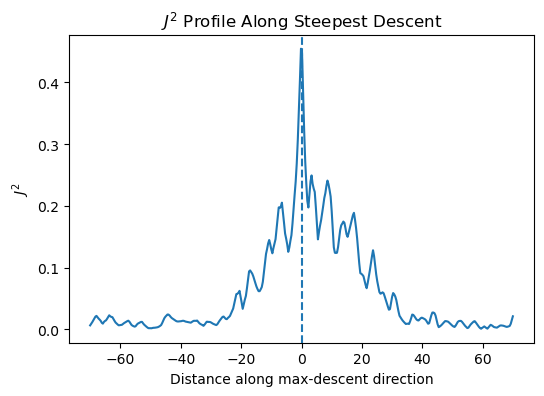

In [9]:
# distance along the cut
L = 70
s = np.linspace(-L, L, 400)

# coordinates along the line
x_line = x0 + s*dx
y_line = y0 + s*dy

# interpolate J^2 along the line
profile_beta1 = map_coordinates(J_squared, [x_line, y_line], order=1)

plt.figure(figsize=(6,4))
plt.plot(s, profile_beta1)
plt.axvline(0, linestyle='--')
plt.xlabel('Distance along max-descent direction')
plt.ylabel(r'$J^2$')
plt.title(r'$J^2$ Profile Along Steepest Descent')
plt.savefig(RESULTS / "J2_1D_Cut_Beta1.png", dpi=300)
plt.show()

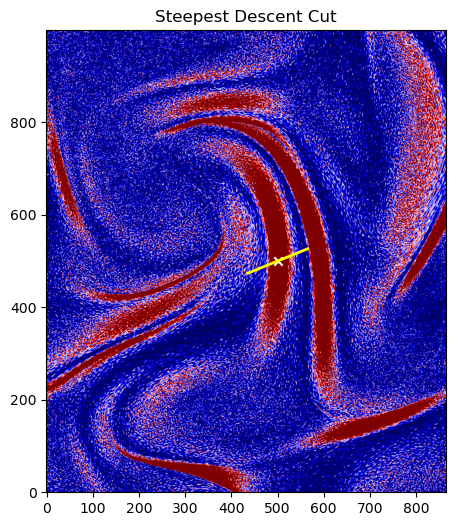

In [10]:
window = 500

plt.figure(figsize=(6,6))

plt.imshow(
    J_squared[x0-window:x0+window, y0-window:y0+window].T,
    cmap='seismic',
    origin='lower', vmax=0.05
)

# shift coordinates to local frame
x_local = x_line - (x0-window)
y_local = y_line - (y0-window)

plt.plot(x_local, y_local, color='yellow', linewidth=2)
plt.scatter(window, window, color='white', marker='x')

plt.title(r'Steepest Descent Cut')
plt.savefig(RESULTS / "J2_1D_Cut_Steepest_Decent_Beta1.png", dpi=300)
plt.show()

In [11]:
#Lets Computer J_total

# # 1. Read the HDF5 file
File_Bx = f'{DATA_ROOT}/beta_p_0.0625/beta_e_1/Bx_ApJ_t40.h5'  # Replace with your file path
File_By = f'{DATA_ROOT}/beta_p_0.0625/beta_e_1/By_ApJ_t40.h5'  # Replace with your file path
File_Bz = f'{DATA_ROOT}/beta_p_0.0625/beta_e_1/Bz_ApJ_t40.h5'  # Replace with your file path

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    data_Bx_filtered = gaussian_fft_filter_2d(data_Bx, k0=0.2 * len(data_Bx))
    data_By_filtered = gaussian_fft_filter_2d(data_By, k0=0.2 * len(data_Bx))
    data_Bz_filtered = gaussian_fft_filter_2d(data_Bz, k0=0.2 * len(data_Bx))
    data_Jx = partial_y_fft(data_Bz_filtered,h)
    data_Jy = -partial_x_fft(data_Bz_filtered,h)
    data_Jz = partial_x_fft(data_By_filtered,h)-partial_y_fft(data_Bx_filtered,h)
    

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2
# J_squared = gaussian_fft_filter_2d(J_squared, k0=0.2 * len(data_Bx))


#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
threshold = np.quantile(J_squared, 0.8)

#Strategy 2: 
# N = 3
# J_squared_rms = np.sqrt(np.mean(J_squared**2))
# threshold = np.mean(J_squared) + N*J_squared_rms

print("Threshold:", threshold)

binary_mask = np.abs(J_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 300 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

Threshold: 0.008738865966080924


In [12]:
# compute gradients
grad_x, grad_y = np.gradient(J_squared)

# point of interest
x0, y0 = 3731, 2294

# gradient at the maximum
gx = grad_x[x0, y0]
gy = grad_y[x0, y0]

# direction of steepest descent
direction = np.array([-gx, -gy])

# normalize
direction = direction / np.linalg.norm(direction)

dx, dy = direction

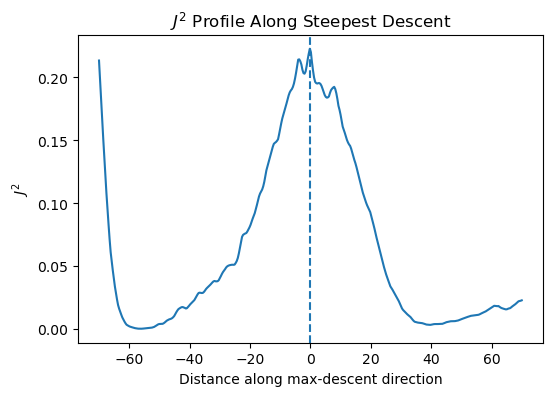

In [13]:
# distance along the cut
L = 70
s = np.linspace(-L, L, 400)

# coordinates along the line
x_line = x0 + s*dx
y_line = y0 + s*dy

# interpolate J^2 along the line
profile_beta00625 = map_coordinates(J_squared, [x_line, y_line], order=1)

plt.figure(figsize=(6,4))
plt.plot(s, profile_beta00625)
plt.axvline(0, linestyle='--')
plt.xlabel('Distance along max-descent direction')
plt.ylabel(r'$J^2$')
plt.title(r'$J^2$ Profile Along Steepest Descent')
plt.savefig(RESULTS / "J2_1D_Cut_Beta0.0625.png", dpi=300)
plt.show()

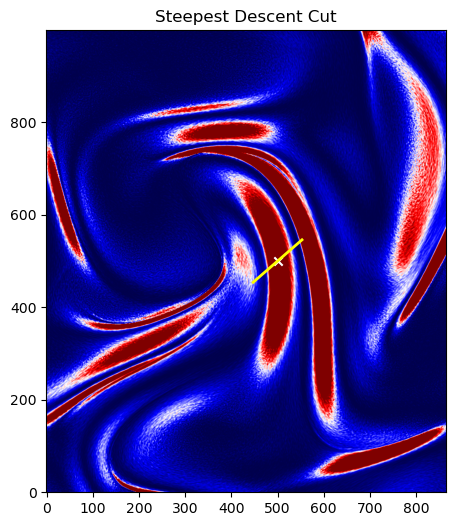

In [14]:
window = 500

plt.figure(figsize=(6,6))

plt.imshow(
    J_squared[x0-window:x0+window, y0-window:y0+window].T,
    cmap='seismic',
    origin='lower', vmax=0.05
)

# shift coordinates to local frame
x_local = x_line - (x0-window)
y_local = y_line - (y0-window)

plt.plot(x_local, y_local, color='yellow', linewidth=2)
plt.scatter(window, window, color='white', marker='x')

plt.title(r'Steepest Descent Cut')
plt.savefig(RESULTS / "J2_1D_Cut_Steepest_Decent_Beta0.0625.png", dpi=300)
plt.show()

In [15]:
#Lets Computer J_total

# # 1. Read the HDF5 file
File_Bx = f'{DATA_ROOT}/beta_p_16/beta_e_1/Bx_ApJ_t40.h5'  # Replace with your file path
File_By = f'{DATA_ROOT}/beta_p_16/beta_e_1/By_ApJ_t40.h5'  # Replace with your file path
File_Bz = f'{DATA_ROOT}/beta_p_16/beta_e_1/Bz_ApJ_t40.h5'  # Replace with your file path

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    data_Bx_filtered = gaussian_fft_filter_2d(data_Bx, k0=0.1 * len(data_Bx))
    data_By_filtered = gaussian_fft_filter_2d(data_By, k0=0.1 * len(data_Bx))
    data_Bz_filtered = gaussian_fft_filter_2d(data_Bz, k0=0.1 * len(data_Bx))
    data_Jx = partial_y_fft(data_Bz_filtered,h)
    data_Jy = -partial_x_fft(data_Bz_filtered,h)
    data_Jz = partial_x_fft(data_By_filtered,h)-partial_y_fft(data_Bx_filtered,h)
    

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2
# J_squared = gaussian_fft_filter_2d(J_squared, k0=0.1 * len(data_Bx))


#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
threshold = np.quantile(J_squared, 0.8)

#Strategy 2: 
# N = 3
# J_squared_rms = np.sqrt(np.mean(J_squared**2))
# threshold = np.mean(J_squared) + N*J_squared_rms

print("Threshold:", threshold)

binary_mask = np.abs(J_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 300 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

Threshold: 0.010702963303514819


In [16]:
# compute gradients
grad_x, grad_y = np.gradient(J_squared)

# point of interest
x0, y0 = 3680, 2388

# gradient at the maximum
gx = grad_x[x0, y0]
gy = grad_y[x0, y0]

# direction of steepest descent
direction = np.array([-gx, -gy])

# normalize
direction = direction / np.linalg.norm(direction)

dx, dy = direction

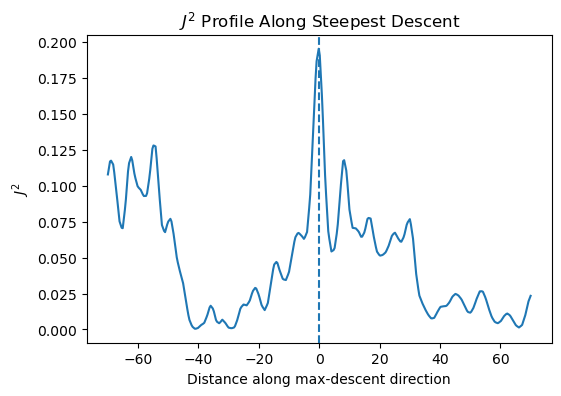

In [17]:
# distance along the cut
L = 70
s = np.linspace(-L, L, 400)

# coordinates along the line
x_line = x0 + s*dx
y_line = y0 + s*dy

# interpolate J^2 along the line
profile_beta16 = map_coordinates(J_squared, [x_line, y_line], order=1)

plt.figure(figsize=(6,4))
plt.plot(s, profile_beta16)
plt.axvline(0, linestyle='--')
plt.xlabel('Distance along max-descent direction')
plt.ylabel(r'$J^2$')
plt.title(r'$J^2$ Profile Along Steepest Descent')
plt.savefig(RESULTS / "J2_1D_Cut_Beta16.png", dpi=300)
plt.show()

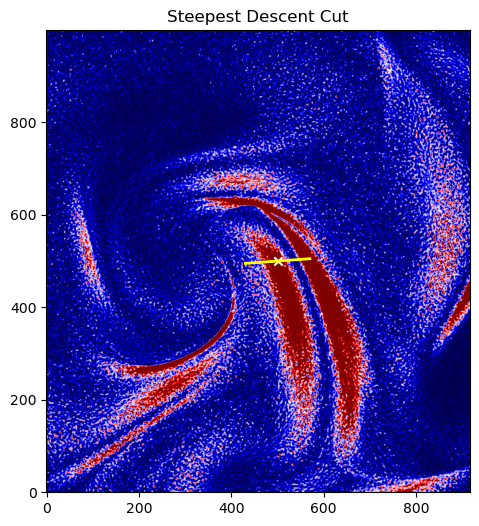

In [18]:
window = 500

plt.figure(figsize=(6,6))

plt.imshow(
    J_squared[x0-window:x0+window, y0-window:y0+window].T,
    cmap='seismic',
    origin='lower', vmax=0.05
)

# shift coordinates to local frame
x_local = x_line - (x0-window)
y_local = y_line - (y0-window)

plt.plot(x_local, y_local, color='yellow', linewidth=2)
plt.scatter(window, window, color='white', marker='x')

plt.title(r'Steepest Descent Cut')
plt.savefig(RESULTS / "J2_1D_Cut_Steepest_Decent_Beta16.png", dpi=300)
plt.show()

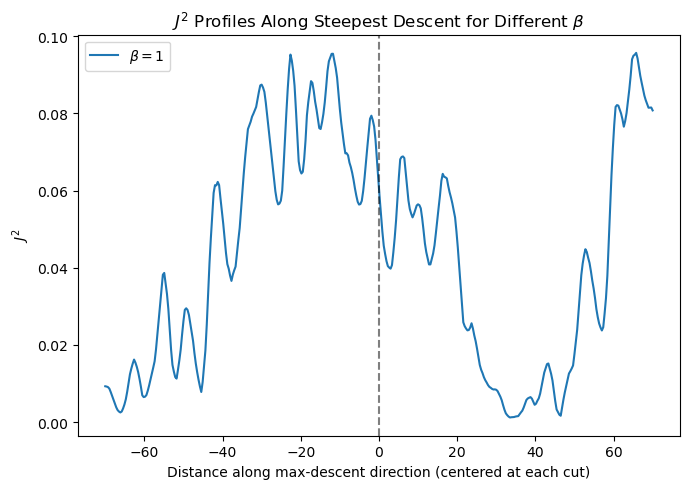

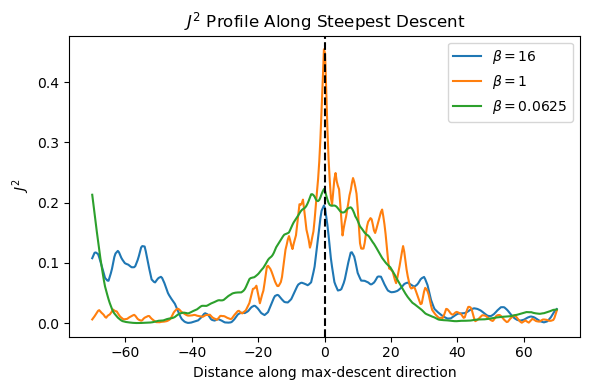

In [24]:
# distance along the cut
L = 70
s = np.linspace(-L, L, 400)

plt.figure(figsize=(6, 4))
plt.plot(s, profile_beta16, label=r'$\beta=16$')
plt.plot(s, profile_beta1, label=r'$\beta=1$')
plt.plot(s, profile_beta00625, label=r'$\beta=0.0625$')
plt.axvline(0, linestyle='--', color='k')
plt.xlabel('Distance along max-descent direction')
plt.ylabel(r'$J^2$')
plt.title(r'$J^2$ Profile Along Steepest Descent')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "J2_1D_Cut_Beta.png", dpi=300)
plt.show()